# G.654.E / LS PremierLink LE125 — Colab 광모드 FEM 검증 보고서

**Python Wave Optics M7 | 실행 가능한 연구용 시뮬레이션 보고서 | 2026-10-19**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kimheeseo/LSCNS/blob/main/COMSOL/g654e_validation/G654E_Colab_Validation.ipynb)

> **핵심 구분:** 이 노트북은 공개된 **MFD = 12.5 µm (1550 nm)** 를 기준으로 이상적인 원형 **step-index** 모델을 *보정*한 뒤, 동일한 물리 문제의 (1) Bessel 독립 해석해, (2) 경계 일치형 radial P1 FEM, (3) 기존 M7 2D 삼각형 P1 FEM을 비교합니다. **실제 LE125 굴절률 프로파일, 제조사 Aeff, 감쇠, 케이블 컷오프의 독립적인 제품 검증 또는 COMSOL 결과 재현은 아닙니다.**

**사용 순서:** `런타임 → 모두 실행` 또는 상단부터 셀 실행 → 입력 파라미터 변경 후 다시 실행 → 표·모드 그림·분산 및 메시 오차 확인 → 마지막 셀에서 결과 ZIP 생성.

원본: [G.654.E 보고서](https://github.com/kimheeseo/LSCNS/blob/main/COMSOL/g654e_validation/G654E_VALIDATION_REPORT.md) · [M7 FEM 엔진](https://github.com/kimheeseo/LSCNS/tree/main/COMSOL/waveoptics_m7/src) · [Colab 파일 폴더](https://github.com/kimheeseo/LSCNS/tree/main/COMSOL/g654e_validation)


## 1. 해석 목적·시험 기준

| 구분 | 기준 / 의미 |
|---|---|
| LS전선 PremierLink LE125 | MFD **12.5 µm @ 1550 nm** (이번 계산의 **보정 목표값**) |
| LS전선 PremierLink LE125 | attenuation ≤ **0.17 dB/km** (현재 해석기 **계산 불가**) |
| ITU-T G.654.E | $D(1550)$ **17–23 ps/(nm·km)**; $S(1550)$ **0.050–0.070 ps/(nm²·km)** |
| 입력 미확정 | 실제 코어 지름, $Δn(r)$, 도핑 프로파일은 본 프로젝트에서 확인되지 않음 |

**사용한 물리 모델**: 고유치 방정식 $(k_0^2 n^2 + \nabla_{\perp}^2)\psi=\beta^2\psi$, $n_\mathrm{eff}=\beta/k_0$,
$A_\mathrm{eff}=(\int I\,dA)^2/\int I^2\,dA$, $D=-(\lambda/c)d^2n_\mathrm{eff}/d\lambda^2$.
MFD에는 **Petermann-II** 와 **second-moment** 두 정의가 있으므로 반드시 구분합니다.

**참고:** [LS전선 통신 브로셔 (2025)](https://fliphtml5.com/plzsm/rgkq/20250925_%ED%86%B5%EC%8B%A0_%EB%B8%8C%EB%A1%9C%EC%85%94/) · [ITU-T G.654 (08/2024)](https://www.itu.int/epublications/publication/itu-t-g-654-2024-08-characteristics-of-a-cut-off-shifted-single-mode-optical-fibre-and-cable)


In [1]:
# @title 2. 실행환경 확인
import sys, json, warnings, platform, zipfile
from pathlib import Path
from dataclasses import replace
import numpy as np
import pandas as pd
import scipy
from scipy.optimize import brentq
from scipy.special import j0, k0 as besselk0
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

RESULT_DIR = Path('G654E_Colab_Results')
RESULT_DIR.mkdir(parents=True, exist_ok=True)
print(f'Python {sys.version.split()[0]} | NumPy {np.__version__} | SciPy {scipy.__version__} | Matplotlib {plt.matplotlib.__version__}')
print('결과 저장 폴더:', RESULT_DIR.resolve())


Python 3.13.5 | NumPy 2.3.5 | SciPy 1.17.0 | Matplotlib 3.10.8
결과 저장 폴더: /mnt/data/g654e_colab/G654E_Colab_Results


In [2]:
# @title 3. 파라미터 입력 (Colab에서 변경 가능)
wavelength_nm = 1550.0 # @param {type:"number"}
core_radius_um = 5.5 # @param {type:"number"}
reference_mfd_um = 12.5 # @param {type:"number"}
fit_delta_n_from_mfd = True # @param {type:"boolean"}
delta_n_if_not_fitting = 0.003478579 # @param {type:"number"}
outer_radius_um = 40.0 # @param {type:"number"}
run_2d_fem = True # @param {type:"boolean"}
run_profile_sensitivity = True # @param {type:"boolean"}

assert 1300 <= wavelength_nm <= 1650, '권장 파장: 1300–1650 nm (결과 외삽 주의)'
assert 1 < core_radius_um < outer_radius_um/2, '코어 반경은 양수이고 외부 경계보다 충분히 작아야 합니다.'
assert reference_mfd_um > 0 and delta_n_if_not_fitting > 0
print('설정:',dict(wavelength_nm=wavelength_nm, core_radius_um=core_radius_um,
                  reference_mfd_um=reference_mfd_um, fit_delta_n_from_mfd=fit_delta_n_from_mfd,
                  run_2d_fem=run_2d_fem))


설정: {'wavelength_nm': 1550.0, 'core_radius_um': 5.5, 'reference_mfd_um': 12.5, 'fit_delta_n_from_mfd': True, 'run_2d_fem': True}


## 4. 수치해석 엔진

아래 두 코드는 **기존 GitHub 파일의 해당 수치 루틴을 노트북 안에 그대로 포함**한 것이므로 Colab에서 대형 저장소를 클론하거나 외부 코드를 다운로드하지 않아도 됩니다.

- `g654e_validation.py` 의 원형 Bessel 해석해·Radial P1 FEM 구현
- `validate_m7_2d.py` 의 2D P1 삼각형 요소 조립, Eigenmode 및 모드 적분 구현

원형 경계 일치 FEM 결과와 **코어 경계를 삼각형 중심점으로 분류하는 기존 2D FEM** 결과의 차이를 확인합니다.


In [3]:
# @title 4-1. Bessel + Radial FEM 원본 루틴 (펼쳐보기)
"""Independent repeatable verification of the M7 scalar Step-index assumptions.
Numerical radial P1 FEM is directly transcribed from COMSOL/waveoptics_m7/src/radial_fem.py
(with equivalent input class). LP01 Bessel oracle is transcribed from fiber_modes.py.
This DOES NOT simulate or validate the actual undisclosed LE125 index profile.
"""
from __future__ import annotations
from dataclasses import dataclass, replace
import numpy as np
from scipy.special import j0,j1,k0 as K0,k1 as K1
from scipy.optimize import brentq, root, minimize_scalar
from scipy.integrate import quad
from numpy.polynomial.legendre import leggauss
from scipy.sparse import coo_matrix
from scipy.sparse.linalg import eigsh
import matplotlib.pyplot as plt
import json
from pathlib import Path
C0=299792458.
SB=(.6961663,.4079426,.8974794);SC=(.0684043**2,.1162414**2,9.896161**2)
def silica_index(w):
 w=float(w)
 return float(np.sqrt(1+sum(b*w*w/(w*w-c) for b,c in zip(SB,SC))))
@dataclass(frozen=True)
class Fiber:
 wavelength_um:float=1.55
 radius_um:float=5.0
 delta_n:float=.003
 domain_halfwidth_um:float=35.
 n_cladding:float|None=None
 @property
 def clad(self):return silica_index(self.wavelength_um) if self.n_cladding is None else self.n_cladding
 @property
 def core(self):return self.clad+self.delta_n
 @property
 def v(self):return 2*np.pi*self.radius_um/self.wavelength_um*np.sqrt(self.core**2-self.clad**2)
def lp01_analytic(f):
 v=f.v
 if not 0<v<2.404825557695772:raise ValueError(f"LP01 oracle limited V<2.405: V={v}")
 def eq(u):
  w=np.sqrt(v*v-u*u)
  return u*j1(u)/j0(u)-w*K1(w)/K0(w)
 u=brentq(eq,max(v*1e-6,1e-8),v*(1-1e-10),xtol=2e-13)
 w=np.sqrt(v*v-u*u)
 ne=float(np.sqrt((2*np.pi*f.core/f.wavelength_um)**2-(u/f.radius_um)**2)*f.wavelength_um/(2*np.pi))
 return dict(V=float(v),u=float(u),w=float(w),n_eff=ne)
def radial_lp01_aeff(f):
 a=lp01_analytic(f);u,w=a['u'],a['w'];radius=f.radius_um
 def shape(t):return j0(u*t)/j0(u) if t<=1 else K0(w*t)/K0(w)
 def d_shape(t):return -u*j1(u*t)/j0(u) if t<=1 else -w*K1(w*t)/K0(w)
 def integrate(power,moment,deriv=False):
  s=d_shape if deriv else shape
  fun=lambda t:s(t)**power*t**moment
  return quad(fun,0,1,epsabs=1e-11,epsrel=1e-10)[0]+quad(fun,1,np.inf,epsabs=1e-11,epsrel=1e-10)[0]
 total=2*np.pi*radius**2*integrate(2,1)
 four=2*np.pi*radius**2*integrate(4,1)
 mom=2*np.pi*radius**4*integrate(2,3)/total
 # Petermann-II: MFD=2 sqrt(2 * \int E^2 r dr / \int (dE/dr)^2 r dr).
 # With t=r/a, denominator has no a^2 and numerator has a^2.
 petermann=2*radius*np.sqrt(2*integrate(2,1)/integrate(2,1,deriv=True))
 return dict(Aeff_um2=float(total**2/four),MFD_2nd_um=float(2*np.sqrt(2*mom)), MFD_petermann_ii_um=float(petermann))
def solve_radial(fiber, core_elements=160, clad_elements=640, outer_radius_um=None):
 outer = fiber.domain_halfwidth_um if outer_radius_um is None else float(outer_radius_um)
 a=fiber.radius_um
 r=np.r_[np.linspace(0,a,core_elements+1),np.linspace(a,outer,clad_elements+1)[1:]]
 x,w=leggauss(4);t=(x+1)/2;phi=np.stack((1-t,t),axis=1)
 h=np.diff(r);rq=r[:-1,None]+h[:,None]*t;weights=h[:,None]*w/2
 mass=np.einsum('eq,qi,qj->eij',weights*rq,phi,phi)
 stiff=((r[1:]**2-r[:-1]**2)/(2*h**2))[:,None,None]*np.array([[1.,-1.],[-1.,1.]])
 indices=np.r_[np.full(core_elements,fiber.core),np.full(clad_elements,fiber.clad)]
 k0=2*np.pi/fiber.wavelength_um
 local=k0**2*indices[:,None,None]**2*mass-stiff
 edges=np.stack((np.arange(len(h)),np.arange(len(h))+1),axis=1)
 rows=np.broadcast_to(edges[:,:,None],local.shape).ravel()
 cols=np.broadcast_to(edges[:,None,:],local.shape).ravel()
 def matrix(v):return coo_matrix((v.ravel(),(rows,cols)),shape=(len(r),len(r))).tocsr()[:-1,:-1]
 A,M=matrix(local),matrix(mass)
 val,vec=eigsh(A,k=1,M=M,sigma=(k0*fiber.core)**2,which='LM',v0=np.ones(len(r)-1),tol=1e-11)
 beta2=float(val[0]);q=vec[:,0]
 residual=np.linalg.norm(A@q-beta2*(M@q))/np.linalg.norm(beta2*(M@q))
 field=np.r_[q,0.]
 if field[0]<0:field=-field
 fieldq=field[edges]@phi.T;intensity=fieldq**2
 wt=2*np.pi*weights*rq;power=np.sum(wt*intensity)
 aeff=power**2/np.sum(wt*intensity**2)
 moment=np.sum(wt*intensity*rq**2)/power
 neff=np.sqrt(beta2)/k0 if beta2>0 else float('nan')
 return dict(n_eff=float(neff),Aeff_um2=float(aeff),MFD_2nd_um=float(2*np.sqrt(2*moment)),residual=float(residual),guided=bool(fiber.clad<neff<fiber.core),outer_radius_um=outer,core_elements=core_elements,clad_elements=clad_elements, radius_um=r,field=field/np.sqrt(power))
def dispersion_lp01(f,step=.003):
 def ne(x):return lp01_analytic(replace(f,wavelength_um=float(x)))['n_eff']
 w=f.wavelength_um;h=step
 d2=(-ne(w+2*h)+16*ne(w+h)-30*ne(w)+16*ne(w-h)-ne(w-2*h))/(12*h*h)
 return float(-(w/C0)*1e12*d2)


In [4]:
# @title 4-2. M7 2D 삼각형 FEM 원본 루틴 (펼쳐보기)
def grid(n,h):
 if not isinstance(n,(int,np.integer)) or isinstance(n,bool) or n<15 or n%2!=1:raise ValueError('odd mesh count>=15')
 if not np.isfinite(h) or h<=0:raise ValueError('positive finite halfwidth')
 xy=np.stack(np.meshgrid(np.linspace(-h,h,n),np.linspace(-h,h,n),indexing='xy'),-1).reshape(-1,2)
 i,j=np.meshgrid(np.arange(n-1),np.arange(n-1),indexing='xy');p=(j*n+i).ravel()
 tris=np.concatenate([np.stack([p,p+1,p+n+1],1),np.stack([p,p+n+1,p+n],1)]).astype(int)
 free=np.flatnonzero((np.abs(xy[:,0])<h-1e-9)&(np.abs(xy[:,1])<h-1e-9))
 return xy,tris,free
def assemble_fem(xy,tri,index):
 p=xy[tri];dx=p[:,1,0]-p[:,0,0];dy=p[:,1,1]-p[:,0,1];ex=p[:,2,0]-p[:,0,0];ey=p[:,2,1]-p[:,0,1]
 det=dx*ey-dy*ex
 if np.any(np.abs(det)<1e-14):raise ValueError('degenerate triangle')
 area=np.abs(det)/2
 gx=np.stack([p[:,1,1]-p[:,2,1],p[:,2,1]-p[:,0,1],p[:,0,1]-p[:,1,1]],1)/det[:,None]
 gy=np.stack([p[:,2,0]-p[:,1,0],p[:,0,0]-p[:,2,0],p[:,1,0]-p[:,0,0]],1)/det[:,None]
 K=area[:,None,None]*(gx[:,:,None]*gx[:,None,:]+gy[:,:,None]*gy[:,None,:])
 b=np.ones((3,3));np.fill_diagonal(b,2)
 M=area[:,None,None]*b[None,:,:]/12
 ni=np.asarray(index(p.mean(1)),float)
 if len(ni)!=len(area) or np.any(ni<=0):raise ValueError('invalid index')
 N=M*ni[:,None,None]**2
 rows=np.broadcast_to(tri[:,:,None],(len(tri),3,3)).ravel()
 cols=np.broadcast_to(tri[:,None,:],(len(tri),3,3)).ravel()
 def csr(v):return coo_matrix((v.ravel(),(rows,cols)),shape=(len(xy),len(xy))).tocsr()
 return csr(K),csr(M),csr(N)
def solve_modes(f,n=81,cores=None,modes=2):
 centers=[(0.,0.)] if cores is None else list(cores)
 c=np.asarray(centers,float)
 xy,tri,free=grid(n,f.domain_halfwidth_um)
 def index(points):
  r2=np.full(len(points),np.inf)
  for xx,yy in centers:r2=np.minimum(r2,(points[:,0]-xx)**2+(points[:,1]-yy)**2)
  return np.where(r2<=f.radius_um**2,f.core,f.clad)
 K,M,N=assemble_fem(xy,tri,index);k0=2*np.pi/f.wavelength_um;A=(k0*k0*N-K)[free][:,free];MM=M[free][:,free]
 vals,vectors=eigsh(A,k=modes,M=MM,sigma=(k0*f.core)**2+.02,which='LM',tol=1e-10,v0=np.random.default_rng(0).normal(size=len(free)))
 order=np.argsort(vals)[::-1];vals=vals[order];vectors=vectors[:,order]
 fields=np.zeros((len(xy),modes));fields[free,:]=vectors
 neff=np.sqrt(np.maximum(0,vals))/k0
 resid=[float(np.linalg.norm(A@vectors[:,i]-vals[i]*(MM@vectors[:,i]))/np.linalg.norm(vals[i]*(MM@vectors[:,i]))) for i in range(modes)]
 return dict(fiber=f,n=n,xy=xy,triangles=tri,free=free,mass=M,neff=neff,fields=fields,guided=(neff>f.clad)&(neff<f.core),residuals=resid,cores=centers)
def scalar_metrics(sol,k=0):
 b=np.array([[1/3,1/3,1/3],[.059715871789770,.470142064105115,.470142064105115],[.470142064105115,.059715871789770,.470142064105115],[.470142064105115,.470142064105115,.059715871789770],[.797426985353087,.101286507323456,.101286507323456],[.101286507323456,.797426985353087,.101286507323456],[.101286507323456,.101286507323456,.797426985353087]])
 weights=np.array([.225,.132394152788506,.132394152788506,.132394152788506,.125939180544827,.125939180544827,.125939180544827])
 tri=sol['triangles'];xyz=sol['xy'][tri];p=sol['fields'][tri,k]
 area=np.abs((xyz[:,1,0]-xyz[:,0,0])*(xyz[:,2,1]-xyz[:,0,1])-(xyz[:,2,0]-xyz[:,0,0])*(xyz[:,1,1]-xyz[:,0,1]))/2
 intensity=np.abs(p@b.T)**2;points=np.einsum('qi,tij->tqj',b,xyz)
 wt=area[:,None]*weights
 power=float(np.sum(wt*intensity));four=float(np.sum(wt*intensity**2))
 center=np.sum(wt[:,:,None]*intensity[:,:,None]*points,axis=(0,1))/power
 r2=np.sum((points-center)**2,axis=2);moment=np.sum(wt*intensity*r2)/power
 return dict(n_eff=float(sol['neff'][k]),Aeff_um2=power**2/four,MFD_2nd_um=float(2*np.sqrt(2*moment)),residual=float(sol['residuals'][k]),centroid_um=center.tolist(),power_integral=power)


## 5. 굴절률 파라미터 보정 및 광학특성

기본 설정(코어 반경 5.5 µm)에서 **$Δn$ 한 개만 MFD 12.5 µm에 보정**합니다. 실제 제품 내부 구조는 역추정할 수 없으므로 이 결과를 측정치 재현으로 표시하지 않습니다. 파장 의존성은 silica Sellmeier와 파장에 대해 일정한 $Δn$ 가정에 따릅니다.


In [5]:
# @title 5-1. Petermann-II 기준 델타-n 보정 / 결과 계산
LAMBDA_UM = wavelength_nm / 1000.0
fiber_base = Fiber(wavelength_um=LAMBDA_UM, radius_um=core_radius_um,
                   delta_n=delta_n_if_not_fitting, domain_halfwidth_um=outer_radius_um)

def calibrated_fiber(radius_um=core_radius_um, wavelength_um=LAMBDA_UM,
                     target_mfd_um=reference_mfd_um):
    def deviation(dn):
        test = Fiber(wavelength_um=wavelength_um, radius_um=radius_um,
                     delta_n=float(dn), domain_halfwidth_um=max(outer_radius_um, 4*radius_um))
        if test.v >= 2.404825557:
            return np.nan
        return radial_lp01_aeff(test)['MFD_petermann_ii_um']-target_mfd_um
    tests=[]
    for dn in np.linspace(0.0005,0.007,110):
        y=deviation(dn)
        if np.isfinite(y):tests.append((float(dn),float(y)))
    bounds=next(((x[0], y[0]) for x,y in zip(tests,tests[1:]) if x[1]*y[1]<0),None)
    if bounds is None:
        raise ValueError('설정된 코어 반경에서 MFD 목표의 단일모드 보정해를 찾지 못했습니다. 코어 반경/MFD를 조정하세요.')
    dn_fit=brentq(deviation,*bounds,xtol=1e-13)
    return Fiber(wavelength_um=wavelength_um, radius_um=radius_um,
                 delta_n=float(dn_fit),domain_halfwidth_um=outer_radius_um)

f = calibrated_fiber() if fit_delta_n_from_mfd else fiber_base
assert f.v < 2.404825557, '독립 LP01 해석해 지원범위를 벗어났습니다 (V >= 2.405).'
ref = lp01_analytic(f)
metrics = radial_lp01_aeff(f)
D1550 = dispersion_lp01(f)  # 입력한 λ에서의 D
S_at_lambda = (dispersion_lp01(replace(f,wavelength_um=LAMBDA_UM+.005))-
               dispersion_lp01(replace(f,wavelength_um=LAMBDA_UM-.005)))/10 # dD/dlambda(nm)
results = dict(wavelength_nm=wavelength_nm, core_radius_um=core_radius_um,
               delta_n=f.delta_n, n_clad=f.clad, n_core=f.core, V=f.v,
               neff_analytic=ref['n_eff'], Aeff_um2=metrics['Aeff_um2'],
               MFD_Petermann_II_um=metrics['MFD_petermann_ii_um'],
               MFD_second_moment_um=metrics['MFD_2nd_um'],
               D_ps_nm_km=D1550, S_ps_nm2_km=S_at_lambda,
               MFD_was_fitted=fit_delta_n_from_mfd)
summary = pd.DataFrame({'계산/가정 값':results}).rename_axis('항목')
display(summary)
print('주의: Petermann-II MFD는 입력값으로 보정' if fit_delta_n_from_mfd else '주의: MFD 보정을 해제했습니다.')


,계산/가정 값
항목,
wavelength_nm,1550.0
core_radius_um,5.5
delta_n,0.003479
n_clad,1.444024
n_core,1.447502
V,2.236018
neff_analytic,1.445719
Aeff_um2,121.922513
MFD_Petermann_II_um,12.5


주의: Petermann-II MFD는 입력값으로 보정


## 6. LP01 모드 필드 분포 (2D) 및 굴절률 단면

아래 원형 모드 분포는 **Bessel 이론해로 생성한 2D 그림**입니다. 실제 2D FEM 계산 그림은 뒤의 별도 검증 단계에서 제공합니다. 모든 그림에서 횡축·종축 단위는 µm입니다.


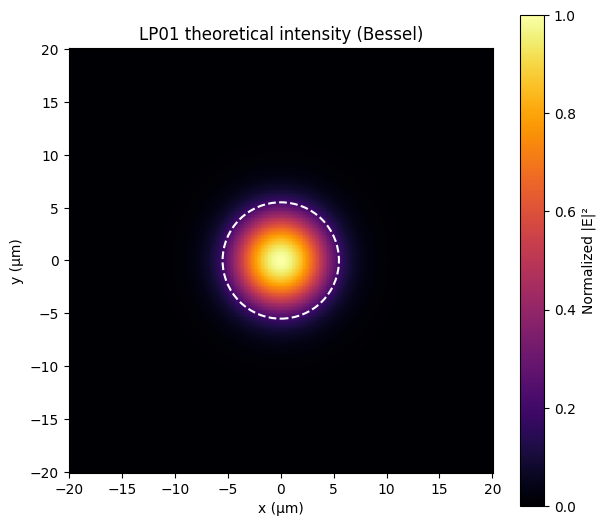

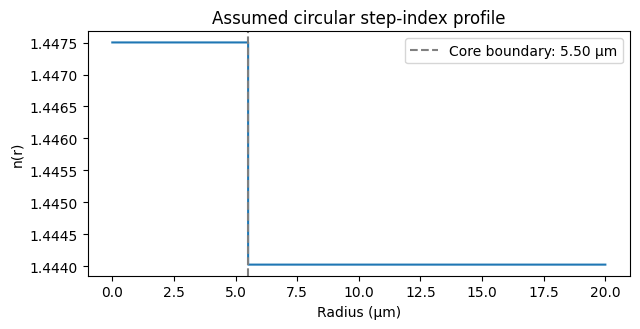

In [6]:
# @title 6-1. 독립 Bessel LP01 필드/굴절률 프로파일 그림
radius_plot = max(3*core_radius_um, 20)
xx = np.linspace(-radius_plot,radius_plot,300)
X,Y=np.meshgrid(xx,xx)
R=np.hypot(X,Y)
u,w=ref['u'],ref['w']
with np.errstate(divide='ignore',invalid='ignore'):
    E=np.where(R<=f.radius_um, j0(u*R/f.radius_um)/j0(u),
               besselk0(w*np.maximum(R,1e-8)/f.radius_um)/besselk0(w))
I=E**2
I/=I.max()
fig,ax=plt.subplots(figsize=(6.2,5.5))
im=ax.pcolormesh(X,Y,I,shading='auto',cmap='inferno',vmin=0,vmax=1)
ax.add_patch(plt.Circle((0,0),f.radius_um,fill=False,edgecolor='white',ls='--',lw=1.5))
ax.set(xlabel='x (µm)',ylabel='y (µm)',title='LP01 theoretical intensity (Bessel)')
ax.set_aspect('equal')
fig.colorbar(im,ax=ax,label='Normalized |E|²')
fig.tight_layout()
fig.savefig(RESULT_DIR/'01_LP01_Bessel_Field.png',dpi=160)
plt.show()

rr=np.linspace(0,radius_plot,600)
fig,ax=plt.subplots(figsize=(6.5,3.4))
ax.step(rr,np.where(rr<=f.radius_um,f.core,f.clad),where='post')
ax.axvline(f.radius_um,color='gray',ls='--',label=f'Core boundary: {f.radius_um:.2f} µm')
ax.set(xlabel='Radius (µm)',ylabel='n(r)',title='Assumed circular step-index profile')
ax.legend();fig.tight_layout()
fig.savefig(RESULT_DIR/'02_Index_Profile.png',dpi=160)
plt.show()


## 7. 경계일치 Radial FEM vs Bessel 해석해

격자 개수와 계산 영역을 바꾸며 실제 FEM 고유치 문제를 다시 풀고 `neff`, `Aeff`, second-moment MFD의 상대/절대 오차를 비교합니다. FEM 고유벡터는 적분으로 정규화합니다.


,elements,outer_radius_um,neff_FEM,neff_abs_error,Aeff_um2,Aeff_error_pct,MFD_second_um,MFD_error_pct,eigen_residual
0,200,30.0,1.445719,1.800000e-07,121.932834,0.008465,12.820015,0.001298,0.0
1,400,35.0,1.445719,6.000000e-08,121.926729,0.003457,12.820063,0.001676,0.0
2,800,40.0,1.445719,2.000000e-08,121.923999,0.001218,12.819935,0.000672,0.0
3,1600,45.0,1.445719,1.000000e-08,121.923006,0.000404,12.819878,0.000227,0.0


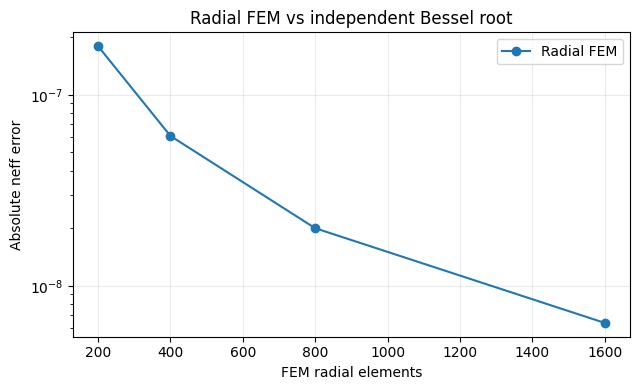

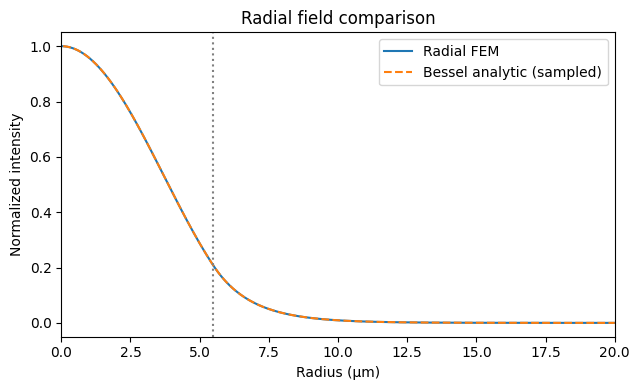

In [7]:
# @title 7-1. Radial FEM 실제 재계산 및 수렴성
mesh_specs=[(40,160,30.),(80,320,35.),(160,640,40.),(320,1280,45.)]
radial_rows=[]
radial_solution=None
for core_e,clad_e,outer in mesh_specs:
    outer=max(outer, 3.0*f.radius_um)
    sol=solve_radial(f,core_elements=core_e,clad_elements=clad_e,outer_radius_um=outer)
    if core_e==160:radial_solution=sol
    radial_rows.append({'elements':core_e+clad_e,'outer_radius_um':outer,
        'neff_FEM':sol['n_eff'],'neff_abs_error':abs(sol['n_eff']-ref['n_eff']),
        'Aeff_um2':sol['Aeff_um2'],
        'Aeff_error_pct':100*(sol['Aeff_um2']/metrics['Aeff_um2']-1),
        'MFD_second_um':sol['MFD_2nd_um'],
        'MFD_error_pct':100*(sol['MFD_2nd_um']/metrics['MFD_2nd_um']-1),
        'eigen_residual':sol['residual']})
radial_df=pd.DataFrame(radial_rows)
display(radial_df.round(8))
assert np.isfinite(radial_df['neff_FEM']).all()

fig,ax=plt.subplots(figsize=(6.5,4))
ax.semilogy(radial_df['elements'],radial_df['neff_abs_error'],'o-',label='Radial FEM')
ax.set(xlabel='FEM radial elements',ylabel='Absolute neff error',title='Radial FEM vs independent Bessel root')
ax.grid(True,alpha=.25);ax.legend();fig.tight_layout()
fig.savefig(RESULT_DIR/'03_Radial_Mesh_Convergence.png',dpi=160)
plt.show()

fig,ax=plt.subplots(figsize=(6.5,4))
r=radial_solution['radius_um'];intensity=radial_solution['field']**2
ax.plot(r,intensity/intensity.max(),label='Radial FEM')
ax.plot(xx[xx>=0],I[150,xx>=0],linestyle='--',label='Bessel analytic (sampled)')
ax.axvline(f.radius_um,color='gray',ls=':')
ax.set(xlabel='Radius (µm)',ylabel='Normalized intensity',title='Radial field comparison')
ax.set_xlim(0,max(3*f.radius_um,20));ax.legend();fig.tight_layout()
fig.savefig(RESULT_DIR/'04_Radial_Field_Comparison.png',dpi=160)
plt.show()


## 8. 분산 $D(\lambda)$ · 기울기 $S$ 및 ITU-T G.654.E 범위

이상적 모델의 $n_{\rm eff}(\lambda)$ 로부터 해석해를 유한 차분하여 $D$ 를 계산합니다. **이는 2D FEM 파장 스윕을 직접 미분한 결과가 아닙니다.** 아래 G.654.E 분산 허용 경계는 1530–1625 nm에서만 표시합니다.


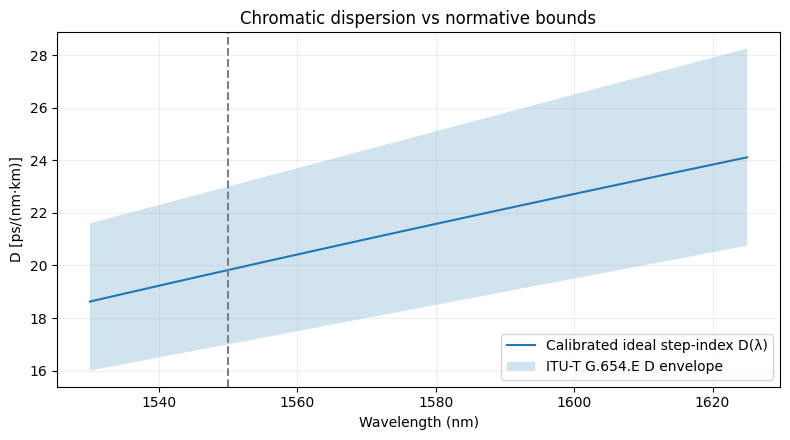

D(1550 nm)=19.8257 ps/(nm·km) [17,23] => True
S(1550 nm)=0.05934 ps/(nm²·km) [0.05,0.07] => True
1530–1625 nm 50 points within nominal D bounds: 50/50


In [8]:
# @title 8-1. 분산 곡선과 ITU-T 허용 범위
lambdas_nm=np.linspace(1530,1625,50)
Dvals=np.array([dispersion_lp01(replace(f,wavelength_um=float(nm)/1000)) for nm in lambdas_nm])
low = 17 + .050*(lambdas_nm-1550)
high= 23 + .070*(lambdas_nm-1550)
Dband_df=pd.DataFrame({'wavelength_nm':lambdas_nm,'D_model':Dvals,'D_lower_G654E':low,
                       'D_upper_G654E':high,'within_band':(Dvals>=low)&(Dvals<=high)})
fig,ax=plt.subplots(figsize=(8,4.5))
ax.plot(lambdas_nm,Dvals,label='Calibrated ideal step-index D(λ)')
ax.fill_between(lambdas_nm,low,high,alpha=.2,label='ITU-T G.654.E D envelope')
ax.axvline(1550,color='gray',ls='--')
ax.set(xlabel='Wavelength (nm)',ylabel='D [ps/(nm·km)]',title='Chromatic dispersion vs normative bounds')
ax.grid(True,alpha=.2);ax.legend();fig.tight_layout()
fig.savefig(RESULT_DIR/'05_Dispersion_ITU_Bounds.png',dpi=160)
plt.show()
# 1550 nm checkpoint is normative. When wavelength input !=1550, recompute at 1550.
f1550=replace(f,wavelength_um=1.55)
D_at1550=dispersion_lp01(f1550)
S_at1550=(dispersion_lp01(replace(f1550,wavelength_um=1.555))-
          dispersion_lp01(replace(f1550,wavelength_um=1.545)))/10.0
print(f'D(1550 nm)={D_at1550:.4f} ps/(nm·km) [17,23] => {17<=D_at1550<=23}')
print(f'S(1550 nm)={S_at1550:.5f} ps/(nm²·km) [0.05,0.07] => {0.05<=S_at1550<=0.07}')
print(f'1530–1625 nm {len(Dvals)} points within nominal D bounds: {int(Dband_df.within_band.sum())}/{len(Dvals)}')


## 9. 기존 M7 2D 삼각형 FEM 재검증 (실제 고유치 계산)

`run_2d_fem=True`일 때 독립적으로 FEM 희소 고유치 문제를 계산합니다. 격자 161×161은 Colab 환경에 따라 수십 초 이상 걸릴 수 있습니다. 저장된 **2D FEM 필드 그림은 Bessel 모드 그림과 별개로 실제 2D P1 계산의 출력**입니다.

**오차 해석:** 해석해와의 일치가 좋아도 실제 제조사 굴절률 분포를 검증한 것은 아닙니다. 기존 솔버는 코어 경계를 삼각형 centroid로 분류하므로 메시별 경계 오차가 발생할 수 있습니다.


,grid,grid_n,triangles,neff_FEM,neff_abs_error,Aeff_um2,Aeff_error_pct,MFD_second_um,MFD_second_error_pct,residual
0,61x61,61,7200,1.445745,0.000026,124.538211,2.145377,12.916382,0.752999,0.0
1,81x81,81,12800,1.445708,0.000011,122.306755,0.315152,12.844589,0.192989,0.0
2,121x121,121,28800,1.445723,0.000004,122.454381,0.436234,12.838149,0.142750,0.0
3,161x161,161,51200,1.445709,0.000010,121.715090,-0.170127,12.815352,-0.035071,0.0


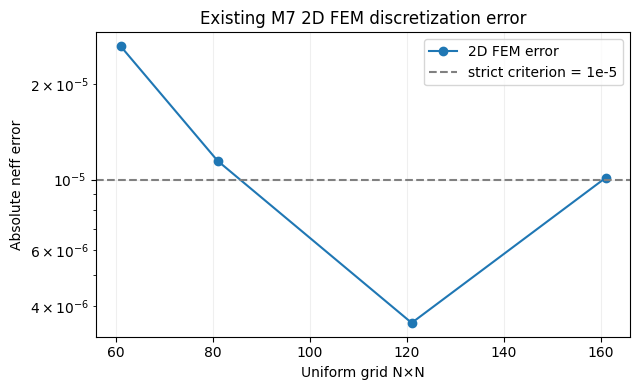

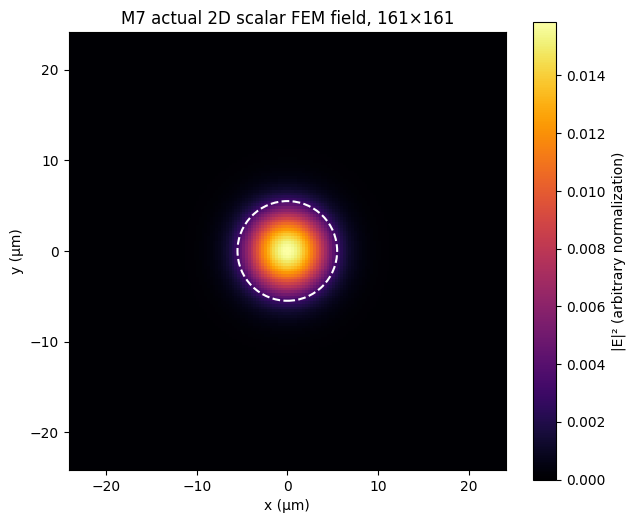

In [9]:
# @title 9-1. 2D FEM 메시 수렴 + 2D FEM 필드
f2d=replace(f,domain_halfwidth_um=max(24.,3.5*f.radius_um))
records=[]
last_solution=None
if run_2d_fem:
    for n in [61,81,121,161]:
        sol=solve_modes(f2d,n=n,modes=1)
        met=scalar_metrics(sol)
        records.append({'grid':f'{n}x{n}','grid_n':n,'triangles':len(sol['triangles']),
                        'neff_FEM':met['n_eff'],'neff_abs_error':abs(met['n_eff']-ref['n_eff']),
                        'Aeff_um2':met['Aeff_um2'],
                        'Aeff_error_pct':100*(met['Aeff_um2']/metrics['Aeff_um2']-1),
                        'MFD_second_um':met['MFD_2nd_um'],
                        'MFD_second_error_pct':100*(met['MFD_2nd_um']/metrics['MFD_2nd_um']-1),
                        'residual':met['residual']})
        if n==161:last_solution=sol
    fem2d_df=pd.DataFrame(records)
    display(fem2d_df.round(8))
    fig,ax=plt.subplots(figsize=(6.5,4))
    ax.semilogy(fem2d_df['grid_n'],fem2d_df['neff_abs_error'],'o-',label='2D FEM error')
    ax.axhline(1e-5,ls='--',color='gray',label='strict criterion = 1e-5')
    ax.set(xlabel='Uniform grid N×N',ylabel='Absolute neff error',title='Existing M7 2D FEM discretization error')
    ax.grid(True,alpha=.2);ax.legend();fig.tight_layout()
    fig.savefig(RESULT_DIR/'06_2D_Mesh_Convergence.png',dpi=160)
    plt.show()
    n=last_solution['n']; xy=last_solution['xy']; ffield=last_solution['fields'][:,0].reshape(n,n)
    fig,ax=plt.subplots(figsize=(6.5,5.4))
    im=ax.pcolormesh(xy[:,0].reshape(n,n),xy[:,1].reshape(n,n),
                     ffield**2,shading='auto',cmap='inferno')
    ax.add_patch(plt.Circle((0,0),f.radius_um,fill=False,edgecolor='white',ls='--',lw=1.5))
    ax.set(xlabel='x (µm)',ylabel='y (µm)',title=f'M7 actual 2D scalar FEM field, {n}×{n}')
    ax.set_aspect('equal');fig.colorbar(im,ax=ax,label='|E|² (arbitrary normalization)')
    fig.tight_layout();fig.savefig(RESULT_DIR/'07_2D_FEM_Field.png',dpi=160);plt.show()
else:
    fem2d_df=pd.DataFrame()
    print('2D FEM 실행을 건너뛰었습니다. 기존 저장된 검증값이 아닌 현재 계산만 집계합니다.')


## 10. 굴절률 프로파일 미확정에 따른 역문제 민감도

실제 코어 반경을 모르므로, 여러 **가정 코어 반경**에서 동일한 12.5 µm MFD에 맞춰 $Δn$ 을 각각 조정할 수 있습니다. 하지만 Aeff·분산 계산값은 서로 달라집니다. 이 표는 **공개 MFD 하나로 코어 구조를 유일하게 복원할 수 없다는 반례**입니다.


,assumed_radius_um,fitted_delta_n,V,Aeff_um2,D_ps_nm_km
0,5.00,0.003313,1.983690,119.334523,18.551768
1,5.25,0.003379,2.103723,120.555132,19.214632
2,5.50,0.003479,2.236018,121.922513,19.825725
3,5.75,0.003613,2.382559,123.426114,20.390618


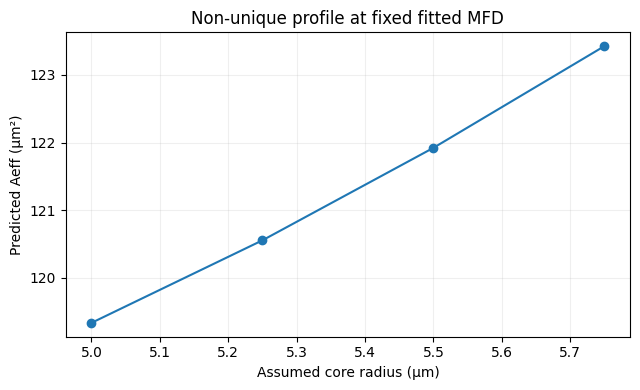

In [10]:
# @title 10-1. 코어 반경 가정별 민감도 (옵션)
sens_rows=[]
if run_profile_sensitivity:
    for radius in [5.,5.25,5.5,5.75,6.]:
        try:
            ff=calibrated_fiber(radius_um=radius)
            mm=radial_lp01_aeff(ff)
            sens_rows.append({'assumed_radius_um':radius,'fitted_delta_n':ff.delta_n,
                              'V':ff.v,'Aeff_um2':mm['Aeff_um2'],
                              'D_ps_nm_km':dispersion_lp01(ff)})
        except ValueError:
            pass
    sensitivity_df=pd.DataFrame(sens_rows)
    display(sensitivity_df.round(6))
    if len(sensitivity_df):
        fig,ax=plt.subplots(figsize=(6.5,4))
        ax.plot(sensitivity_df['assumed_radius_um'],sensitivity_df['Aeff_um2'],'o-')
        ax.set(xlabel='Assumed core radius (µm)',ylabel='Predicted Aeff (µm²)',
               title='Non-unique profile at fixed fitted MFD')
        ax.grid(True,alpha=.2);fig.tight_layout()
        fig.savefig(RESULT_DIR/'08_Profile_Sensitivity.png',dpi=160)
        plt.show()
else:
    sensitivity_df=pd.DataFrame()
    print('민감도 계산 생략')


## 11. 자동 판정 및 실행 보고서 생성

검증 결과는 **모델 내부 수치 적합성**과 **공개 G.654.E 분산 범위에 들어가는지**를 검사합니다. 공개된 MFD는 보정 목표이므로 독립 통과 기준으로 해석하지 않습니다. 2D FEM의 엄격한 오차 기준 미달도 감추지 않습니다.


In [11]:
# @title 11-1. 테스트 판정 · 결과 파일 저장 · ZIP 패키지
last=radial_df.iloc[-1]
checks={
 'Radial FEM |neff error| <1e-6': bool(last['neff_abs_error']<1e-6),
 'Radial FEM |Aeff error| <1%': bool(abs(last['Aeff_error_pct'])<1),
 'Radial FEM |second-moment MFD error| <1%':bool(abs(last['MFD_error_pct'])<1),
 'Radial FEM net neff error improves':bool(last['neff_abs_error']<radial_df.iloc[0]['neff_abs_error']),
 'D(1550) in ITU-T G.654.E 17–23':bool(17<=D_at1550<=23),
 'S(1550) in ITU-T G.654.E 0.05–0.07':bool(0.05<=S_at1550<=0.07),
 'D(1530–1625) within modeled bound':bool(Dband_df.within_band.all()),
}
if fit_delta_n_from_mfd:
    checks['Petermann-II MFD fit residual <0.01 µm (calibration ONLY)']=bool(abs(metrics['MFD_petermann_ii_um']-reference_mfd_um)<.01)
if run_2d_fem:
    row=fem2d_df.iloc[-1]
    checks.update({
     '2D FEM fine grid |neff error| <1e-5':bool(row['neff_abs_error']<1e-5),
     '2D FEM fine grid |Aeff error| <2%':bool(abs(row['Aeff_error_pct'])<2),
     '2D FEM fine grid |MFD error| <2%':bool(abs(row['MFD_second_error_pct'])<2),
     '2D FEM fine grid residual <1e-8':bool(row['residual']<1e-8),
    })
pass_count=sum(checks.values());total=len(checks)
check_df=pd.DataFrame([{'테스트':k,'판정':'PASS' if v else 'FAIL'} for k,v in checks.items()])
display(check_df)
print(f'수치 시험 통과: {pass_count}/{total}; FAIL={total-pass_count}')

radial_df.to_csv(RESULT_DIR/'radial_mesh_table.csv',index=False)
Dband_df.to_csv(RESULT_DIR/'dispersion_band.csv',index=False)
if run_2d_fem: fem2d_df.to_csv(RESULT_DIR/'fem2d_mesh_table.csv',index=False)
if len(sensitivity_df):sensitivity_df.to_csv(RESULT_DIR/'profile_sensitivity.csv',index=False)
record={'model':'calibrated circular step-index, weak-guidance scalar LP01',
        'not_validated':['actual LE125 index profile','actual attenuation','manufacturer Aeff',
                         'measured cutoff','COMSOL full-vector equivalence'],
        'parameters_and_results':results,'D_1550':D_at1550,'S_1550':S_at1550,
        'checks':checks,'passed':pass_count,'total_checks':total,
        'source_repo':'https://github.com/kimheeseo/LSCNS/tree/main/COMSOL/g654e_validation'}
(RESULT_DIR/'summary.json').write_text(json.dumps(record,ensure_ascii=False,indent=2),encoding='utf-8')
md_report=f"""# G.654.E Colab 재계산 보고서

- 모델: 원형 step-index 약유도 scalar LP01, LE125 실제 굴절률 프로파일 미사용
- MFD: {metrics['MFD_petermann_ii_um']:.4f} µm ({'보정값' if fit_delta_n_from_mfd else '계산값'})
- 코어 반경: {f.radius_um:.3f} µm (가정)
- Δn: {f.delta_n:.9f} ({'MFD 보정' if fit_delta_n_from_mfd else '수동 입력'})
- 유효굴절률: {ref['n_eff']:.9f}
- Aeff: {metrics['Aeff_um2']:.3f} µm²
- D1550: {D_at1550:.4f} ps/(nm·km)
- S1550: {S_at1550:.5f} ps/(nm²·km)
- 현재 실행 검증: {pass_count}/{total} PASS
- 제한: 감쇠·케이블 컷오프·실제 제조사 프로파일/사양의 독립 검증 없음.
"""
(RESULT_DIR/'EXECUTION_REPORT.md').write_text(md_report,encoding='utf-8')
zipname=Path('G654E_Colab_Results.zip')
with zipfile.ZipFile(zipname,'w',zipfile.ZIP_DEFLATED) as z:
    for file in RESULT_DIR.rglob('*'):
        if file.is_file():z.write(file,arcname=file.relative_to(RESULT_DIR.parent))
print('생성 완료:',zipname.resolve(),'크기:',zipname.stat().st_size,'bytes')
print('보고서:',(RESULT_DIR/'EXECUTION_REPORT.md').resolve())
from IPython.display import FileLink
display(FileLink(str(zipname)))
# Colab 다운로드: 필요할 때 아래 두 줄의 주석을 해제하세요.
# from google.colab import files
# files.download(str(zipname))


,테스트,판정
0,Radial FEM |neff error| <1e-6,PASS
1,Radial FEM |Aeff error| <1%,PASS
2,Radial FEM |second-moment MFD error| <1%,PASS
3,Radial FEM net neff error improves,PASS
4,D(1550) in ITU-T G.654.E 17–23,PASS
5,S(1550) in ITU-T G.654.E 0.05–0.07,PASS
6,D(1530–1625) within modeled bound,PASS
7,Petermann-II MFD fit residual <0.01 µm (calibr...,PASS
8,2D FEM fine grid |neff error| <1e-5,FAIL
9,2D FEM fine grid |Aeff error| <2%,PASS


수치 시험 통과: 11/12; FAIL=1
생성 완료: /mnt/data/g654e_colab/G654E_Colab_Results.zip 크기: 401221 bytes
보고서: /mnt/data/g654e_colab/G654E_Colab_Results/EXECUTION_REPORT.md


/mnt/data/g654e_colab/G654E_Colab_Results.zip

### 결론과 다음 연구 단계

기존 M7의 **원형 대칭 step-index 약유도 FEM**은 Bessel 기준해와 높은 일치도를 보일 수 있습니다. 반면 기존 **2D 삼각형 FEM**은 경계 표현 때문에 `neff` 메시 수렴의 비단조성을 확인할 수 있습니다. **제조사 LE125에 대해 독립적으로 검증된 항목은 아직 없습니다.** 독립 제품 검증을 위해 실제 굴절률 $n(r)$ 또는 MFD 외의 실측 $Aeff$, $D$, $S$, cutoff 입력을 확보해야 합니다.

다음 기술 개발 우선순위: (1) 코어 경계 적합 mesh (Gmsh), (2) 2D Full-vector FEM, (3) 실제 다층 굴절률 프로파일, (4) 실측 스펙과의 별도 오차 검증, (5) 실효손실 및 굽힘 모델.
